# BÀI THỰC HÀNH SỐ 2: K-NN VÀ HỒI QUY TUYẾN TÍNH

**Họ và tên:** Trần Đức Vũ Hào  
**Nội dung:** Thực hiện đầy đủ các mục A.1-A.3 và B.1-B.5 theo tài liệu thực hành.

Notebook được tổ chức theo từng bài độc lập. Mỗi bài nêu rõ cách chia dữ liệu, tham số của mô hình, kết quả đánh giá và nhận xét ngắn.

## 0. Chuẩn bị môi trường và các hàm dùng chung

- `locate_guide()` tìm thư mục dữ liệu khi chạy từ thư mục gốc hoặc từ `Week1/work`.
- `knn_regression()` dùng khoảng cách Euclid và `np.argpartition` để lấy `k` láng giềng.
- `score_regression()` trả về MSE, MAE và R². R² không xác định nếu tập đánh giá chỉ có một mẫu.

In [1]:
from pathlib import Path
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=6, suppress=True)


def locate_guide():
    candidates = [
        Path.cwd() / "Week1" / "guide",
        Path.cwd() / "guide",
        Path.cwd().parent / "guide",
    ]
    for folder in candidates:
        if folder.is_dir():
            return folder.resolve()
    raise FileNotFoundError("Không tìm thấy thư mục Week1/guide")


def as_2d(values):
    array = np.asarray(values, dtype=float)
    return array.reshape(-1, 1) if array.ndim == 1 else array


def knn_regression(train_x, train_y, query_x, k):
    train_x = as_2d(train_x)
    query_x = as_2d(query_x)
    train_y = np.asarray(train_y, dtype=float).reshape(-1)

    if not 1 <= k <= len(train_x):
        raise ValueError("k phải nằm trong [1, số mẫu huấn luyện]")

    predictions = []
    for query in query_x:
        distances = np.linalg.norm(train_x - query, axis=1)
        nearest = np.argpartition(distances, k - 1)[:k]
        predictions.append(train_y[nearest].mean())
    return np.asarray(predictions)


def score_regression(actual, predicted):
    actual = np.asarray(actual, dtype=float).reshape(-1)
    predicted = np.asarray(predicted, dtype=float).reshape(-1)
    result = {
        "MSE": mean_squared_error(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "R2": np.nan,
    }
    if len(actual) >= 2:
        result["R2"] = r2_score(actual, predicted)
    return result


def metric_table(rows):
    return pd.DataFrame(rows).set_index("Mô hình")


def load_fuel(path):
    raw = pd.read_csv(path)
    return pd.DataFrame({
        "Tax": raw["Tax"],
        "Dlic": 1000 * raw["Drivers"] / raw["Pop"],
        "Income": raw["Income"],
        "LogMiles": np.log2(raw["Miles"]),
        "Fuel": 1000 * raw["FuelC"] / raw["Pop"],
    })


GUIDE = locate_guide()
print("Thư mục dữ liệu:", GUIDE)

Thư mục dữ liệu: D:\MachineLearning\Week1\guide


# A. PHƯƠNG PHÁP K-NEAREST NEIGHBORS

## A.1. Dự đoán GPA từ SAT

Theo đề: dùng 64 mẫu đầu làm training, 20 mẫu còn lại làm validation và chọn `k = 8`.

In [2]:
sat_gpa = pd.read_csv(GUIDE / "SAT_GPA.csv")
sat_train = sat_gpa.loc[:63, ["SAT"]].to_numpy()
gpa_train = sat_gpa.loc[:63, "GPA"].to_numpy()
sat_valid = sat_gpa.loc[64:, ["SAT"]].to_numpy()
gpa_valid = sat_gpa.loc[64:, "GPA"].to_numpy()

gpa_knn = knn_regression(sat_train, gpa_train, sat_valid, k=8)
result_a1 = score_regression(gpa_valid, gpa_knn)

display(pd.DataFrame({
    "SAT": sat_valid.ravel(),
    "GPA thực tế": gpa_valid,
    "GPA dự đoán": gpa_knn,
    "Sai số": gpa_valid - gpa_knn,
}).round(4))
display(pd.DataFrame([result_a1], index=["K-NN, k=8"]).round(6))

,SAT,GPA thực tế,GPA dự đoán,Sai số
0,1893,3.51,3.3925,0.1175
1,1832,3.52,3.2750,0.2450
2,1850,3.52,3.2950,0.2250
3,1934,3.54,3.3975,0.1425
4,1861,3.58,3.2950,0.2850
5,1931,3.58,3.3975,0.1825
6,1933,3.59,3.3975,0.1925
7,1778,3.59,3.2588,0.3312
8,1975,3.60,3.3900,0.2100
9,1934,3.60,3.3975,0.2025


,MSE,MAE,R2
"K-NN, k=8",0.081378,0.271188,-10.951519


**Nhận xét A.1:** K-NN lấy trung bình GPA của 8 sinh viên có SAT gần nhất. Tập validation nằm ở cuối tệp và có GPA cao hơn phần lớn tập train, nên K-NN khó ngoại suy vượt miền GPA đã quan sát.

## A.2. Dự đoán áp suất từ nhiệt độ sôi

Theo đề: 16 mẫu đầu làm training, mẫu cuối làm validation và `k = 4`.

In [3]:
temperatures = np.array([
    194.5, 194.3, 197.9, 198.4, 199.4, 199.9, 200.9, 201.1,
    201.4, 201.3, 203.6, 204.6, 209.5, 208.6, 210.7, 211.9, 212.2,
])
pressures = np.array([
    20.79, 20.79, 22.40, 22.67, 23.15, 23.35, 23.89, 23.99,
    24.02, 24.01, 25.14, 26.57, 28.49, 27.76, 29.04, 29.88, 30.06,
])

pressure_knn = knn_regression(
    temperatures[:16], pressures[:16], temperatures[16:], k=4
)
result_a2 = score_regression(pressures[16:], pressure_knn)

print(f"Nhiệt độ validation: {temperatures[16]:.1f} °F")
print(f"Áp suất thực tế:      {pressures[16]:.4f}")
print(f"Áp suất dự đoán:      {pressure_knn[0]:.4f}")
display(pd.DataFrame([result_a2], index=["K-NN, k=4"]).round(6))

Nhiệt độ validation: 212.2 °F
Áp suất thực tế:      30.0600
Áp suất dự đoán:      28.7925


,MSE,MAE,R2
"K-NN, k=4",1.606556,1.2675,NaN


**Nhận xét A.2:** Validation chỉ có một mẫu nên MSE và MAE vẫn tính được, nhưng R² không xác định vì không có độ biến thiên giữa nhiều giá trị thật để so sánh.

## A.3. K-NN dự báo mức tiêu thụ nhiên liệu

Các biến được tạo đúng theo đề:

- `Fuel = 1000 × FuelC / Pop`.
- `Dlic = 1000 × Drivers / Pop`.
- `LogMiles = log2(Miles)`.
- Feature theo thứ tự: `Tax`, `Dlic`, `Income`, `LogMiles`.

Dùng 40 mẫu đầu để huấn luyện, 11 mẫu sau để validation và `k = 6`.

In [4]:
fuel = load_fuel(GUIDE / "fuel.txt")
fuel_features = ["Tax", "Dlic", "Income", "LogMiles"]

fuel_x_train = fuel.loc[:39, fuel_features].to_numpy()
fuel_y_train = fuel.loc[:39, "Fuel"].to_numpy()
fuel_x_valid = fuel.loc[40:, fuel_features].to_numpy()
fuel_y_valid = fuel.loc[40:, "Fuel"].to_numpy()

fuel_knn = knn_regression(
    fuel_x_train, fuel_y_train, fuel_x_valid, k=6
)
result_a3 = score_regression(fuel_y_valid, fuel_knn)

display(pd.DataFrame({
    "Fuel thực tế": fuel_y_valid,
    "Fuel dự đoán": fuel_knn,
    "Sai số": fuel_y_valid - fuel_knn,
}).round(4))
display(pd.DataFrame([result_a3], index=["K-NN, k=6"]).round(6))

,Fuel thực tế,Fuel dự đoán,Sai số
0,711.7331,655.9030,55.8301
1,697.0528,638.4561,58.5967
2,638.2311,638.4561,-0.2250
3,681.1001,611.9270,69.1731
4,591.4999,655.9030,-64.4030
5,691.0227,644.4898,46.5329
6,681.0311,588.0445,92.9867
7,576.0697,605.0998,-29.0301
8,562.4109,662.6531,-100.2422
9,581.7937,584.9524,-3.1587


,MSE,MAE,R2
"K-NN, k=6",6956.363786,65.316405,-0.139373


# B. PHƯƠNG PHÁP HỒI QUY TUYẾN TÍNH

## B.1. Linear Regression trên `fuel.txt`

Dùng đúng 40 mẫu đầu làm training và 11 mẫu còn lại làm validation. Đánh giá MSE, MAE và R² trên cả hai tập.

In [5]:
fuel_linear = LinearRegression().fit(fuel_x_train, fuel_y_train)
fuel_train_pred = fuel_linear.predict(fuel_x_train)
fuel_valid_pred = fuel_linear.predict(fuel_x_valid)

coefficients_b1 = pd.Series(
    [fuel_linear.intercept_, *fuel_linear.coef_],
    index=["Intercept", *fuel_features],
    name="Hệ số",
)
comparison_b1 = metric_table([
    {"Mô hình": "Linear - training", **score_regression(fuel_y_train, fuel_train_pred)},
    {"Mô hình": "Linear - validation", **score_regression(fuel_y_valid, fuel_valid_pred)},
])

display(coefficients_b1.to_frame().round(6))
display(comparison_b1.round(6))

,Hệ số
Intercept,135.142023
Tax,-1.903012
Dlic,0.418592
Income,-0.006229
LogMiles,19.593856


,MSE,MAE,R2
Mô hình,,,
Linear - training,3344.785764,44.209736,0.55156
Linear - validation,6253.362639,60.615490,-0.02423


**Nhận xét B.1:** Chênh lệch giữa kết quả training và validation cho biết khả năng tổng quát hóa. R² validation âm nghĩa là trên 11 mẫu cuối, mô hình còn kém hơn baseline luôn dự đoán trung bình của chính tập validation.

## B.2. Hồi quy nhiên liệu trên toàn bộ dữ liệu: NumPy và Scikit-learn

Phần này đối chiếu nghiệm least-squares bằng `np.linalg.lstsq` với `LinearRegression`. Hai cách phải cho hệ số và dự đoán gần như nhau.

In [6]:
fuel_x_all = fuel[fuel_features].to_numpy()
fuel_y_all = fuel["Fuel"].to_numpy()

fuel_design = np.column_stack([np.ones(len(fuel_x_all)), fuel_x_all])
weights_numpy, *_ = np.linalg.lstsq(fuel_design, fuel_y_all, rcond=None)

fuel_sklearn_all = LinearRegression().fit(fuel_x_all, fuel_y_all)
weights_sklearn = np.r_[fuel_sklearn_all.intercept_, fuel_sklearn_all.coef_]

compare_weights = pd.DataFrame({
    "NumPy lstsq": weights_numpy,
    "Scikit-learn": weights_sklearn,
    "Chênh lệch tuyệt đối": np.abs(weights_numpy - weights_sklearn),
}, index=["Intercept", *fuel_features])

display(compare_weights.round(10))
print("Hai nghiệm gần bằng nhau:", np.allclose(weights_numpy, weights_sklearn))

,NumPy lstsq,Scikit-learn,Chênh lệch tuyệt đối
Intercept,154.192845,154.192845,0.0
Tax,-4.227983,-4.227983,0.0
Dlic,0.471871,0.471871,0.0
Income,-0.006135,-0.006135,0.0
LogMiles,18.545275,18.545275,0.0


Hai nghiệm gần bằng nhau: True


## B.3. SAT và GPA: Pearson, Linear Regression và so sánh K-NN

Yêu cầu:

1. Tính Pearson giữa SAT và GPA.
2. Dùng 64 mẫu đầu làm training, 20 mẫu sau làm validation.
3. Lập phương trình hồi quy và vẽ đường hồi quy.
4. Tính MSE, MAE, R² trên validation.
5. So sánh với K-NN `k = 8` của A.1.

Pearson(SAT, GPA) = 0.637184
Phương trình: GPA = 0.838210 + 0.001318 × SAT


,MSE,MAE,R2
Mô hình,,,
Linear Regression,0.072638,0.248804,-9.667975
"K-NN, k=8",0.081378,0.271188,-10.951519


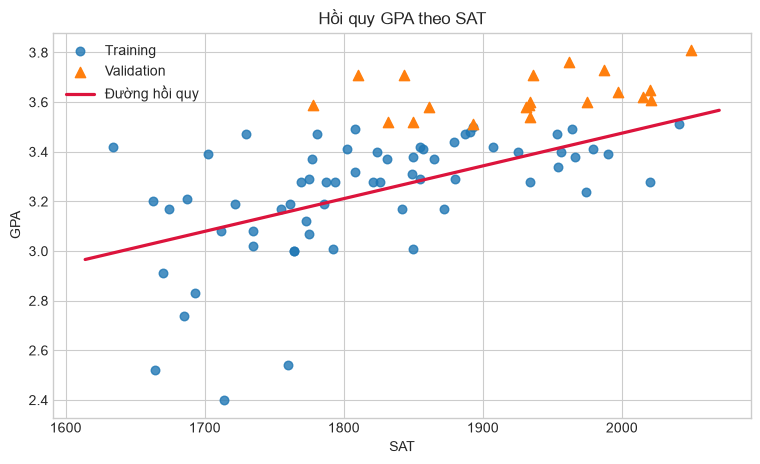

In [7]:
sat_all = sat_gpa["SAT"].to_numpy()
gpa_all = sat_gpa["GPA"].to_numpy()
pearson = np.corrcoef(sat_all, gpa_all)[0, 1]

sat_linear = LinearRegression().fit(sat_train, gpa_train)
gpa_linear = sat_linear.predict(sat_valid)

result_b3 = metric_table([
    {"Mô hình": "Linear Regression", **score_regression(gpa_valid, gpa_linear)},
    {"Mô hình": "K-NN, k=8", **score_regression(gpa_valid, gpa_knn)},
])

print(f"Pearson(SAT, GPA) = {pearson:.6f}")
print(
    "Phương trình: GPA = "
    f"{sat_linear.intercept_:.6f} + {sat_linear.coef_[0]:.6f} × SAT"
)
display(result_b3.round(6))

draw_x = np.linspace(sat_all.min() - 20, sat_all.max() + 20, 200)
draw_y = sat_linear.predict(draw_x.reshape(-1, 1))

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(sat_train.ravel(), gpa_train, s=38, alpha=.8, label="Training")
ax.scatter(sat_valid.ravel(), gpa_valid, marker="^", s=55, label="Validation")
ax.plot(draw_x, draw_y, color="crimson", linewidth=2.3, label="Đường hồi quy")
ax.set(title="Hồi quy GPA theo SAT", xlabel="SAT", ylabel="GPA")
ax.legend()
plt.show()

**Nhận xét B.3:** Pearson dương cho thấy SAT và GPA có xu hướng đồng biến tuyến tính. Do tệp được chia theo thứ tự, 20 mẫu cuối có GPA cao hơn miền training; Linear Regression có thể ngoại suy theo độ dốc, còn K-NN chỉ lấy trung bình các GPA đã thấy.

## B.4. Hồi quy độ dày nội trung mạc

Mô hình theo đúng đề:

`BEDAYNTM = β0 + β1·TUOI + β2·CHOLESTEROL + β3·GLUCOSE + β4·HA + β5·BMI`

- Phần a: xác định hệ số bằng toàn bộ 100 mẫu.
- Phần b: fit lại bằng 80 mẫu đầu, dự đoán 20 mẫu cuối, tính kỳ vọng và phương sai sai số.

In [8]:
ntm = pd.read_csv(GUIDE / "vidu4_lin_reg.txt", sep=r"\s+")
ntm_features = ["TUOI", "CHOLESTEROL", "GLUCOSE", "HA", "BMI"]
ntm_x = ntm[ntm_features].to_numpy()
ntm_y = ntm["BEDAYNTM"].to_numpy()

ntm_full_model = LinearRegression().fit(ntm_x, ntm_y)
ntm_full_coefficients = pd.Series(
    [ntm_full_model.intercept_, *ntm_full_model.coef_],
    index=["β0", "β1 TUOI", "β2 CHOLESTEROL", "β3 GLUCOSE", "β4 HA", "β5 BMI"],
    name="Hệ số từ 100 mẫu",
)

ntm_train_x, ntm_test_x = ntm_x[:80], ntm_x[80:]
ntm_train_y, ntm_test_y = ntm_y[:80], ntm_y[80:]
ntm_split_model = LinearRegression().fit(ntm_train_x, ntm_train_y)
ntm_test_pred = ntm_split_model.predict(ntm_test_x)
ntm_errors = ntm_test_y - ntm_test_pred

display(ntm_full_coefficients.to_frame().round(6))
print(f"Kỳ vọng sai số E[e]   = {ntm_errors.mean():.6f}")
print(f"Phương sai sai số Var = {ntm_errors.var():.6f}")
print(f"Độ lệch chuẩn sai số  = {ntm_errors.std():.6f}")

,Hệ số từ 100 mẫu
β0,-0.108029
β1 TUOI,0.009947
β2 CHOLESTEROL,0.038470
β3 GLUCOSE,0.007670
β4 HA,0.002181
β5 BMI,-0.000207


Kỳ vọng sai số E[e]   = 0.079989
Phương sai sai số Var = 0.221003
Độ lệch chuẩn sai số  = 0.470109


## B.5. Giá bất động sản: Linear Regression và K-NN

Theo đề:

- Bỏ cột số thứ tự và dùng các cột `X2` đến `X6` trong tệp: tuổi nhà, khoảng cách MRT, số cửa hàng, vĩ độ và kinh độ.
- 350 mẫu đầu làm training, 64 mẫu còn lại làm validation.
- Linear Regression và K-NN với `k = 18`.
- So sánh tổng bình phương sai số RSS.

,RSS,MSE,MAE,R2
Mô hình,,,,
Linear Regression,4228.146942,66.064796,6.125478,0.586036
"K-NN, k=18",2809.293457,43.895210,4.781771,0.724951


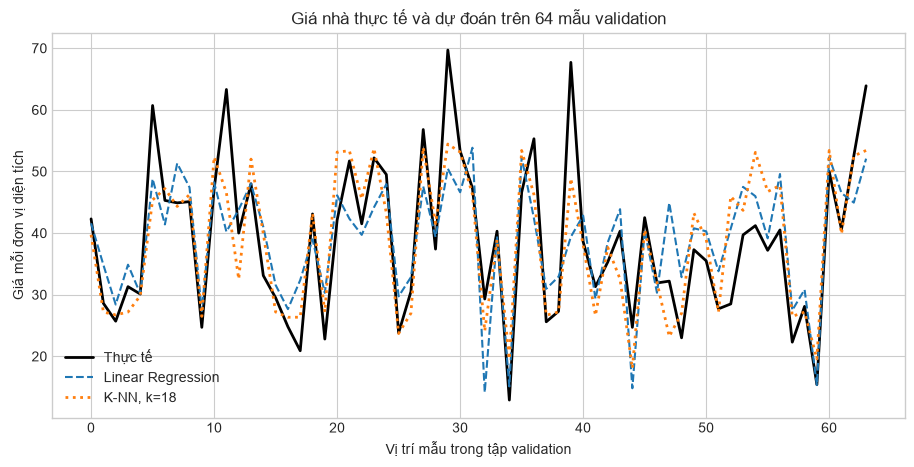

In [9]:
houses = pd.read_csv(GUIDE / "real_estate.csv")
house_features = [
    "X2 house age",
    "X3 distance to the nearest MRT station",
    "X4 number of convenience stores",
    "X5 latitude",
    "X6 longitude",
]
house_target = "Y house price of unit area"

house_x = houses[house_features].to_numpy()
house_y = houses[house_target].to_numpy()
house_train_x, house_valid_x = house_x[:350], house_x[350:]
house_train_y, house_valid_y = house_y[:350], house_y[350:]

house_linear_model = LinearRegression().fit(house_train_x, house_train_y)
house_linear_pred = house_linear_model.predict(house_valid_x)
house_knn_pred = knn_regression(
    house_train_x, house_train_y, house_valid_x, k=18
)

def rss(actual, predicted):
    return np.sum((np.asarray(actual) - np.asarray(predicted)) ** 2)

result_b5 = metric_table([
    {
        "Mô hình": "Linear Regression",
        "RSS": rss(house_valid_y, house_linear_pred),
        **score_regression(house_valid_y, house_linear_pred),
    },
    {
        "Mô hình": "K-NN, k=18",
        "RSS": rss(house_valid_y, house_knn_pred),
        **score_regression(house_valid_y, house_knn_pred),
    },
])
display(result_b5.round(6))

fig, ax = plt.subplots(figsize=(11, 5))
positions = np.arange(len(house_valid_y))
ax.plot(positions, house_valid_y, color="black", linewidth=2, label="Thực tế")
ax.plot(positions, house_linear_pred, linestyle="--", label="Linear Regression")
ax.plot(positions, house_knn_pred, linestyle=":", linewidth=2, label="K-NN, k=18")
ax.set(
    title="Giá nhà thực tế và dự đoán trên 64 mẫu validation",
    xlabel="Vị trí mẫu trong tập validation",
    ylabel="Giá mỗi đơn vị diện tích",
)
ax.legend()
plt.show()

## Kết luận

- K-NN dự đoán bằng thông tin cục bộ từ các mẫu gần nhất; kết quả phụ thuộc mạnh vào `k`, thang đo và mật độ dữ liệu.
- Linear Regression học một quan hệ tuyến tính toàn cục và có thể ngoại suy, nhưng không mô tả tốt quan hệ phi tuyến.
- Việc so sánh phải dùng cùng cách chia dữ liệu và cùng metric. R² âm trên validation không phải lỗi chương trình; nó cho biết mô hình kém hơn baseline trung bình trên tập đó.
- Các kết quả trên tuân theo đúng số mẫu train/validation và giá trị `k` được yêu cầu trong tài liệu thực hành.